# 05. Delay Prediction Model: how well can the timetable alone predict delay?

**Project:** Buffer Delay Allocation Engine (Analytics Capstone Project, Team T19)
**Team:** Vaibhav Maheshwari (BA05057), Prashansa Naomi Konduru (BA05042), Anil Kumar (BA05008)
**Faculty:** Mr. Nikhil D Jonathan
**Data:** `aa_clean_v1.0.parquet` (tag `data-v1.0`): 1,641,071 American Airlines mainline flights, 1 Jan 2025 to 31 Aug 2026

**What this notebook does.** Before an airline can decide where to put buffer, it needs to know *which turnarounds are risky*, and it must know this **in advance**,
from the published timetable only. This notebook builds and tests two prediction models that use **only timetable facts** (hour, airport, distance, season, planned ground time and how far into the aircraft's day it is):

* **Model A (outbound delay):** predicts how late the next flight will leave, in minutes, and whether it will be 15 or more minutes late.
* **Model B (inbound risk):** predicts how many minutes late the *incoming* aircraft will be. This is the "delay that needs absorbing", and notebook 06 uses it to decide where to put buffer.

We compare each model with simple baselines, so we can say honestly how much the model adds.

## How to run this notebook

You need one data file, **`aa_clean_v1.0.parquet`** (68 MB, the cleaned flight data from D2), and these Python packages: pandas, numpy, matplotlib, pyarrow, scikit-learn, lightgbm.
It takes about 2 to 4 minutes and needs about 4 GB of free memory (a normal laptop or free Google Colab is enough). Then choose *Restart and Run All*.

| Where you run it | What to do |
|---|---|
| **Your laptop** (Jupyter, VS Code, Anaconda) | Put `aa_clean_v1.0.parquet` in the same folder as this notebook (or in a folder called `data`). If a package is missing, run `pip install pandas numpy matplotlib pyarrow scikit-learn lightgbm` once. |
| **Google Colab** | Upload this notebook (File, then Upload notebook). Run the first code cell. When it asks, click *Choose files* and select `aa_clean_v1.0.parquet` (or upload the file to the Colab file panel first). Nothing needs to be installed. |

The notebook checks the data file against its published checksum, so you know it is the exact dataset from D2. Charts and tables are saved in a
folder called `modelling_outputs` next to the notebook (or `docs/modelling` if it is run inside the project repository).

## Words used in this notebook

| Word | Meaning |
|---|---|
| **Timetable-only** | The model sees only what is known when the schedule is published. It never sees the actual delay, taxi time, weather or anything that happens on the day. |
| **Baseline** | A very simple way of predicting (for example "always predict the average"). A model is only useful if it beats its baselines. |
| **MAE** | Mean absolute error: how many minutes off the prediction is on average. Lower is better. |
| **R²** | Share of the ups and downs in delay that the model explains. 0 means no better than the average; 1 means perfect. |
| **AUC** | For "late or not": the chance that a flight that really was late gets a higher risk score than one that was not. 0.5 is a coin toss, 1.0 is perfect. |
| **Training / validation / test** | Jan to Sep 2025 (learn), Oct to Dec 2025 (choose settings), Jan to Aug 2026 (final exam, used once). |

## 1. Setup and data check

In [1]:
import sys, hashlib, json, warnings
from pathlib import Path

# 1. Check that the packages we need are installed (on Google Colab they already are).
PKGS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "pyarrow": "pyarrow", "sklearn": "scikit-learn", "lightgbm": "lightgbm"}          # import name -> pip name
missing = []
for module, pip_name in PKGS.items():
    try:
        __import__(module)
    except ImportError:
        missing.append(pip_name)
if missing:
    raise ImportError("Please install the missing packages, then run this cell again:\n    pip install " + " ".join(missing))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10,
                     "legend.frameon": False, "figure.autolayout": True})
BLUE, ORANGE, RED, GREEN, GREY, LIGHT = "#1F3A5F", "#E08A1E", "#C0392B", "#2E8B57", "#8A94A6", "#C9D3E3"
SPLITS = ["train", "validate", "test"]
SEED = 42
RESULTS = {}          # every number we quote is stored here and saved to a .json file at the end
thousands = FuncFormatter(lambda v, pos: f"{v:,.0f}")

# 2. Find the data file: next to the notebook, in 'data' folders, in the Colab file area, or in Downloads.
FILENAME = "aa_clean_v1.0.parquet"
EXPECTED_SHA256 = "3a18a9eafffa77ae74db70579be84255f8b04978efdcdb84524bd2900297f14a"   # published in data/CHECKSUMS.sha256
IN_COLAB = "google.colab" in sys.modules

def locate():
    here = Path.cwd().resolve()
    places = []
    for folder in [here, *here.parents]:
        places += [folder, folder / "data", folder / "data" / "processed"]
    places += [Path("/content"), Path("/content/data"), Path("/content/drive/MyDrive"),
               Path.home() / "Downloads", Path.home() / "Desktop",
               Path("/Volumes/workspace/default/bufferengine/processed")]          # Databricks Volume used by this project
    places += sorted(Path("/Volumes").glob("*/*/*/processed")) if Path("/Volumes").exists() else []   # any other Databricks Volume
    for folder in places:
        if (folder / FILENAME).exists():
            return folder / FILENAME
    return None

PARQUET = locate()
if PARQUET is None and IN_COLAB:
    from google.colab import files
    print(f"Please choose the file {FILENAME} from your computer (68 MB). The upload takes about a minute.")
    files.upload()
    PARQUET = locate()
if PARQUET is None:
    raise FileNotFoundError(f"Could not find {FILENAME}. Put it in the same folder as this notebook (or in a folder called 'data'), "
                            "then run again. On Google Colab, run this cell again and choose the file when asked.")

# 3. Where to save charts and tables.
in_repo = PARQUET.parent.name == "processed" and PARQUET.parent.parent.name == "data" and (PARQUET.parent.parent.parent / "docs").exists()
OUT = (PARQUET.parent.parent.parent / "docs" / "modelling") if in_repo else Path.cwd() / "modelling_outputs"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

def say(text):
    display(Markdown(text))

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o

def write_results(filename):
    (OUT / filename).write_text(json.dumps(_clean(RESULTS), indent=1))
    print(f"Saved {filename} and {len(list(FIG.glob('*.png')))} chart files in the folder '{OUT.name}'.")

# 4. Make sure this is exactly the published dataset.
actual = hashlib.sha256(PARQUET.read_bytes()).hexdigest()
print("Data file          :", PARQUET.name)
print("Python / pandas    :", sys.version.split()[0], "/", pd.__version__)
print("Checksum matches D2:", actual == EXPECTED_SHA256)
assert actual == EXPECTED_SHA256, "This file is not the published aa_clean_v1.0.parquet (tag data-v1.0). Please download it again."

Data file          : aa_clean_v1.0.parquet
Python / pandas    : 3.13.16 / 3.1.0
Checksum matches D2: True


## Building the turnaround table

A **turnaround** is the stop on the ground between two flights of the same aircraft. The buffer question lives here, so every model in this
project works on one row per turnaround. We rebuild the table directly from `aa_clean_v1.0`, so nothing else is needed.

**In plain words, the code below does five things:**
1. Puts each aircraft's flights in time order.
2. Looks at the aircraft's previous flight for every flight.
3. Keeps the pair only if both flights flew, the first landed where the second takes off, they are on the same day, and the planned gap is above zero.
4. Records the **scheduled ground time** (planned gap in minutes), the **inbound delay** `A` (arrival delay of the first flight) and the **outbound delay** `D` (departure delay of the second flight).
5. Adds facts that are known from the timetable alone (hour, airport, distance, how many flights the aircraft has already flown that day). These are the only things the prediction models are allowed to use.

`A` and `D` are limited to the 0.5% and 99.5% levels of the *training* period, so a few extreme flights cannot dominate the averages.

In [2]:
COLS = ["FlightDate", "Month", "DayOfWeek", "Tail_Number", "Origin", "Dest", "Distance", "crs_dep_min", "crs_arr_min",
        "DepDelay", "ArrDelay", "Cancelled", "Diverted", "is_operated", "crs_dep_utc", "crs_arr_utc", "split"]
df = pd.read_parquet(PARQUET, columns=COLS)
df["FlightDate"] = pd.to_datetime(df["FlightDate"])
print(f"{len(df):,} flights loaded, {df.FlightDate.min().date()} to {df.FlightDate.max().date()}")

# limits for extreme delays, learned on the training period only
cap_lo, cap_hi = df.loc[(df.split == "train") & df.ArrDelay.notna(), "ArrDelay"].quantile([0.005, 0.995]).values
dcap_lo, dcap_hi = df.loc[(df.split == "train") & df.DepDelay.notna(), "DepDelay"].quantile([0.005, 0.995]).values
TOP10 = df.Origin.value_counts().head(10).index.tolist()                     # ten busiest departure airports
daily_cancel = df.groupby("FlightDate").Cancelled.mean()
STORM = set(daily_cancel[daily_cancel > 0.10].index)                          # disruption days: more than 10% of flights cancelled
AIRPORTS = sorted(set(df.Origin) | set(df.Dest))

d = df.loc[df.Tail_Number.notna()].sort_values(["Tail_Number", "crs_dep_utc"]).copy()
day = d.groupby(["Tail_Number", "FlightDate"])
d["legno"] = day.cumcount() + 1                                               # which flight of the aircraft's day this is (timetable fact)
d["mins_since_first"] = d.crs_dep_min - day.crs_dep_min.transform("min")      # minutes since the aircraft's first planned departure of the day
g = d.groupby("Tail_Number", sort=False)
d["prev_dest"] = g["Dest"].shift(); d["prev_origin"] = g["Origin"].shift(); d["prev_dist"] = g["Distance"].shift()
d["prev_arr_utc"] = g["crs_arr_utc"].shift(); d["prev_date"] = g["FlightDate"].shift()
d["prev_dep_hr"] = g["crs_dep_min"].shift() // 60; d["prev_arr_hr"] = g["crs_arr_min"].shift() // 60
d["A_raw"] = g["ArrDelay"].shift()
d["prev_operated"] = g["is_operated"].shift().eq(True); d["prev_notdiv"] = g["Diverted"].shift().eq(0)
d["sg"] = (d.crs_dep_utc - d.prev_arr_utc).dt.total_seconds() / 60            # scheduled ground time in minutes

link = (d.is_operated & (d.Diverted == 0) & d.prev_operated & d.prev_notdiv & (d.prev_dest == d.Origin)
        & (d.sg > 0) & (d.FlightDate == d.prev_date))
T = d.loc[link, ["Tail_Number", "Origin", "prev_origin", "FlightDate", "split", "Month", "DayOfWeek", "crs_dep_min", "sg", "Distance",
                 "prev_dist", "legno", "mins_since_first", "prev_dep_hr", "prev_arr_hr", "A_raw", "DepDelay"]].rename(
    columns={"Origin": "station", "DepDelay": "D_raw"}).dropna(subset=["A_raw", "D_raw"]).copy()
T["A"] = T.A_raw.clip(cap_lo, cap_hi); T["D"] = T.D_raw.clip(dcap_lo, dcap_hi)
T["hr"] = (T.crs_dep_min // 60).clip(0, 23)
T["hub"] = T.station.isin(TOP10).astype(int)
T["storm"] = T.FlightDate.isin(STORM)
for c in ["station", "prev_origin"]:
    T[c] = pd.Categorical(T[c], categories=AIRPORTS)
T = T.reset_index(drop=True)
del d, g, day, link, df                                                       # free memory

print(f"Turnarounds built: {len(T):,}   (disruption days: {len(STORM)}; ten busiest airports: {', '.join(TOP10)})")
display(T.groupby("split").agg(turnarounds=("sg", "size"), first_day=("FlightDate", "min"), last_day=("FlightDate", "max"),
                               median_ground_min=("sg", "median"), mean_inbound_delay=("A", "mean"), mean_outbound_delay=("D", "mean")).loc[SPLITS].round(1))
RESULTS["n_turnarounds"] = int(len(T)); RESULTS["n_storm_days"] = len(STORM); RESULTS["top10"] = TOP10

1,641,071 flights loaded, 2025-01-01 to 2026-08-31


Turnarounds built: 1,060,740   (disruption days: 27; ten busiest airports: DFW, CLT, MIA, ORD, PHX, PHL, LAX, DCA, MCO, LGA)


,turnarounds,first_day,last_day,median_ground_min,mean_inbound_delay,mean_outbound_delay
split,,,,,,
train,474633,2025-01-01,2025-09-30,61.0,5.9,15.9
validate,160835,2025-10-01,2025-12-31,61.0,4.0,13.6
test,425272,2026-01-01,2026-08-31,60.0,4.8,17.0


## 2. What the models are allowed to see

Prediction models can cheat without meaning to: if one of the inputs already contains the answer (for example the actual taxi time), the results look great but are useless in real life.
To prevent this, we list the **only** inputs allowed, and the code stops with an error if any banned input slips in.

**Allowed (all known when the timetable is published):**

| Input | Plain meaning |
|---|---|
| `Month`, `DayOfWeek` | Season and weekday. |
| `hr` | Planned departure hour of the next flight. |
| `sg` | Planned ground time in minutes. |
| `Distance`, `prev_dist` | Length of the next flight and of the one that is arriving. |
| `station`, `prev_origin` | The airport where the turnaround happens, and where the arriving flight came from. |
| `legno`, `mins_since_first` | How many flights the aircraft has already been scheduled for that day, and how many minutes since its first planned departure. |
| `prev_dep_hr`, `prev_arr_hr` | Planned departure and arrival hour of the arriving flight. |

**Banned (only known after the fact):** the actual delays (`A`, `D`, `A_raw`, `D_raw`), actual times, taxi times, cancellation or diversion outcomes, and whether the day is a disruption day.

In [3]:
FEATS = ["Month", "DayOfWeek", "hr", "sg", "Distance", "prev_dist", "legno", "mins_since_first", "prev_dep_hr", "prev_arr_hr", "station", "prev_origin"]
BANNED = {"A", "D", "A_raw", "D_raw", "storm", "split", "FlightDate", "Tail_Number", "hub", "crs_dep_min"}
assert not (set(FEATS) & BANNED), "A banned input is in the feature list"
tr, va, te = [T[T.split == s] for s in SPLITS]
print(f"Training {len(tr):,} | validation {len(va):,} | test {len(te):,} turnarounds")
print("Inputs used (", len(FEATS), "):", ", ".join(FEATS))
print("Leak check passed: none of the banned inputs is used.")
T["late"] = (T.D_raw >= 15).astype(int)                       # outbound flight left 15 or more minutes late
T["Apos"] = T.A.clip(lower=0)                                   # inbound delay (0 if early or on time): what needs absorbing
tr, va, te = [T[T.split == s] for s in SPLITS]
print(f"Share of outbound flights 15+ min late: training {100*tr.late.mean():.1f}%, validation {100*va.late.mean():.1f}%, test {100*te.late.mean():.1f}%")

Training 474,633 | validation 160,835 | test 425,272 turnarounds
Inputs used ( 12 ): Month, DayOfWeek, hr, sg, Distance, prev_dist, legno, mins_since_first, prev_dep_hr, prev_arr_hr, station, prev_origin
Leak check passed: none of the banned inputs is used.
Share of outbound flights 15+ min late: training 27.0%, validation 26.0%, test 29.1%


## 3. Model A: predicting the outbound delay

**Baselines.** (1) always predict the training average; (2) predict the average for the planned hour; (3) predict the average for the airport *and* hour (with the airport average pulled towards the hourly average when it has few flights).
**Model.** A gradient-boosted tree model (LightGBM): it learns by building many small decision trees, each correcting the previous ones. It is a standard, free, and fast choice for tables like ours.
It stops adding trees when the validation error stops improving, which prevents over-fitting.

In [4]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

def scores(y, yhat):
    e = np.asarray(y) - np.asarray(yhat)
    return dict(MAE=float(np.abs(e).mean()), RMSE=float(np.sqrt((e ** 2).mean())), R2=float(1 - (e ** 2).sum() / ((y - np.mean(y)) ** 2).sum()))

# ---- baselines (learned on training only)
m0 = tr.D.mean()
by_hr = tr.groupby("hr").D.mean()
ah = tr.groupby(["station", "hr"], observed=True).D.agg(["sum", "count"])
K = 20
def baseline(frame, kind):
    if kind == 0: return np.full(len(frame), m0)
    h = frame.hr.map(by_hr).fillna(m0).values
    if kind == 1: return h
    idx = pd.MultiIndex.from_arrays([frame.station.astype(str).values, frame.hr.values])
    t = ah.reindex(idx)
    s, c = t["sum"].fillna(0).values, t["count"].fillna(0).values
    return (s + K * h) / (c + K)

params = dict(n_estimators=1500, learning_rate=0.05, num_leaves=63, min_child_samples=200, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
reg = lgb.LGBMRegressor(**params)
reg.fit(tr[FEATS], tr.D, eval_set=[(va[FEATS], va.D)], eval_metric="l1", callbacks=[lgb.early_stopping(50, verbose=False)])
print(f"Model A stopped at {reg.best_iteration_} trees")

rows = []
for s, F in [("validate", va), ("test", te)]:
    for name, yhat in [("1 Training average", baseline(F, 0)), ("2 Average by hour", baseline(F, 1)), ("3 Average by airport and hour", baseline(F, 2)),
                       ("4 LightGBM model", reg.predict(F[FEATS]))]:
        rows.append(dict(period=s, predictor=name, **scores(F.D.values, yhat)))
regtab = pd.DataFrame(rows)
display(regtab.round(3).set_index(["period", "predictor"]))
RESULTS["model_A_regression"] = rows

Model A stopped at 252 trees


MAE    RMSE     R2
period   predictor                                           
validate 1 Training average             24.844  41.918 -0.003
         2 Average by hour              24.445  41.731  0.006
         3 Average by airport and hour  24.150  41.637  0.010
         4 LightGBM model               21.689  40.712  0.054
test     1 Training average             26.760  47.735 -0.001
         2 Average by hour              26.228  47.365  0.015
         3 Average by airport and hour  25.997  47.234  0.020
         4 LightGBM model               24.988  45.970  0.072

In [5]:
t_ = regtab[regtab.period == "test"].set_index("predictor")
gain_pct = 100 * (1 - t_.loc["4 LightGBM model", "MAE"] / t_.loc["3 Average by airport and hour", "MAE"])
say(f"""**What we see.** On the unseen **test** period, the model's average error is **{t_.loc['4 LightGBM model','MAE']:.1f} minutes**, against **{t_.loc['1 Training average','MAE']:.1f}** for the plain average and
**{t_.loc['3 Average by airport and hour','MAE']:.1f}** for the airport-and-hour average (the model's error is {gain_pct:.1f}% lower than the airport-and-hour average). R² on test is **{t_.loc['4 LightGBM model','R2']:.3f}**.

**What this means in plain words.** Delay on the day depends mostly on things a timetable cannot know (weather, a technical fault, a late crew, the delay of the aircraft's earlier flights). So
timetable-only prediction is **modest by design**: it ranks which flights are riskier, but it will not tell you the exact delay of one flight. A low R² here is expected, and it is the honest result.
What matters for buffer allocation is whether the model can **rank** turnarounds well, which we check next.""")

**What we see.** On the unseen **test** period, the model's average error is **25.0 minutes**, against **26.8** for the plain average and
**26.0** for the airport-and-hour average (the model's error is 3.9% lower than the airport-and-hour average). R² on test is **0.072**.

**What this means in plain words.** Delay on the day depends mostly on things a timetable cannot know (weather, a technical fault, a late crew, the delay of the aircraft's earlier flights). So
timetable-only prediction is **modest by design**: it ranks which flights are riskier, but it will not tell you the exact delay of one flight. A low R² here is expected, and it is the honest result.
What matters for buffer allocation is whether the model can **rank** turnarounds well, which we check next.

## 4. Model A as a "will it be late?" warning

Most users care less about minutes than about a yes or no: *will the next flight leave 15 or more minutes late?* We train a second version that gives a **risk score between 0 and 100%**.
We then check two things: (1) does it **rank** flights well (AUC), and (2) are the percentages **honest**: when it says 40%, are about 40% really late? (This is called calibration.)

Late-warning model stopped at 166 trees


AUC   Brier  LogLoss
period   predictor                                               
validate 1 Always the training late-rate  0.5000  0.1924   0.5731
         2 Late-rate by airport and hour  0.6058  0.1876   0.5605
         3 LightGBM model                 0.6705  0.1763   0.5334
test     1 Always the training late-rate  0.5000  0.2067   0.6041
         2 Late-rate by airport and hour  0.6190  0.1994   0.5861
         3 LightGBM model                 0.7034  0.1809   0.5422

,turnarounds,predicted late (%),observed late (%)
decile,,,
1,42528,9.3,10.7
2,42527,13.1,14.1
3,42527,16.1,17.4
4,42527,19.2,20.5
5,42527,22.5,24.0
6,42528,26.3,27.4
7,42527,30.9,31.7
8,42526,36.9,36.8
9,42527,45.8,44.0


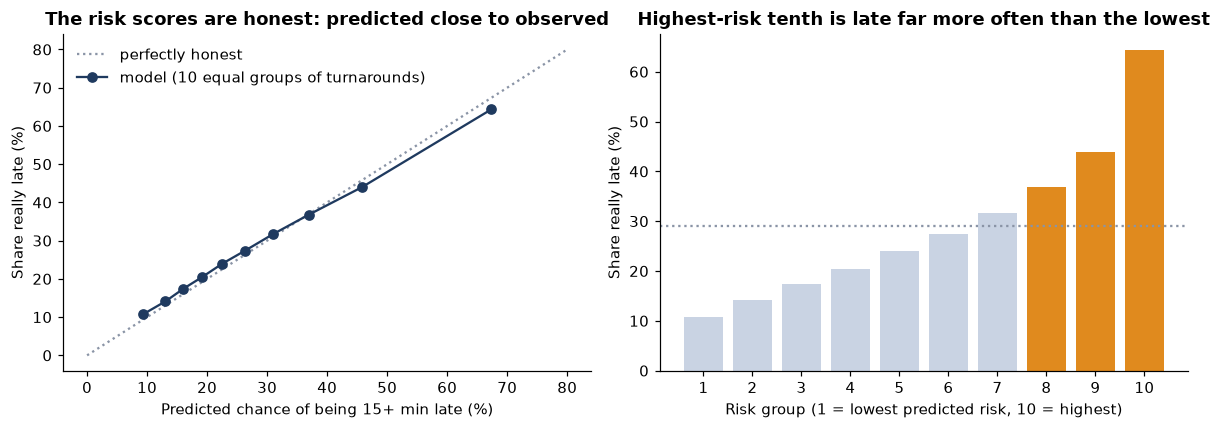

**What we see.** On the unseen test period the late-warning model has an AUC of **0.703** (the airport-and-hour baseline: 0.619; a coin toss would be 0.500).
The tenth of turnarounds with the **highest** risk score is late **64%** of the time; the tenth with the **lowest** is late only **11%** (overall: 29%).
That is a **6.0 times** difference using the timetable alone. The model is useful for *ranking*, which is what buffer allocation needs.

In [6]:
base_rate = tr.late.mean()
ah_late = tr.groupby(["station", "hr"], observed=True).late.agg(["sum", "count"]); by_hr_late = tr.groupby("hr").late.mean()
def base_late(frame):
    h = frame.hr.map(by_hr_late).fillna(base_rate).values
    idx = pd.MultiIndex.from_arrays([frame.station.astype(str).values, frame.hr.values])
    t = ah_late.reindex(idx); s, c = t["sum"].fillna(0).values, t["count"].fillna(0).values
    return (s + K * h) / (c + K)

pc = dict(params); pc["n_estimators"] = 1500
clf = lgb.LGBMClassifier(**pc)
clf.fit(tr[FEATS], tr.late, eval_set=[(va[FEATS], va.late)], eval_metric="auc", callbacks=[lgb.early_stopping(50, verbose=False)])
print(f"Late-warning model stopped at {clf.best_iteration_} trees")

rows = []
for s, F in [("validate", va), ("test", te)]:
    for name, p in [("1 Always the training late-rate", np.full(len(F), base_rate)), ("2 Late-rate by airport and hour", base_late(F)), ("3 LightGBM model", clf.predict_proba(F[FEATS])[:, 1])]:
        rows.append(dict(period=s, predictor=name, AUC=float(roc_auc_score(F.late, p)) if np.std(p) > 0 else 0.5, Brier=float(brier_score_loss(F.late, p)), LogLoss=float(log_loss(F.late, np.clip(p, 1e-4, 1 - 1e-4)))))
clftab = pd.DataFrame(rows)
display(clftab.round(4).set_index(["period", "predictor"]))
RESULTS["model_A_classification"] = rows
RESULTS["late_rate"] = dict(train=float(tr.late.mean()), validate=float(va.late.mean()), test=float(te.late.mean()))

# calibration and lift on the test period
te = te.copy(); te["p_late"] = clf.predict_proba(te[FEATS])[:, 1]
te["decile"] = pd.qcut(te.p_late, 10, labels=False, duplicates="drop") + 1
cal = te.groupby("decile").agg(turnarounds=("late", "size"), predicted=("p_late", "mean"), observed=("late", "mean"))
display(pd.DataFrame({"turnarounds": cal.turnarounds, "predicted late (%)": (100 * cal.predicted).round(1), "observed late (%)": (100 * cal.observed).round(1)}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([0, 80], [0, 80], ls=":", color=GREY, label="perfectly honest")
ax[0].plot(100 * cal.predicted, 100 * cal.observed, "o-", color=BLUE, label="model (10 equal groups of turnarounds)")
ax[0].set_xlabel("Predicted chance of being 15+ min late (%)"); ax[0].set_ylabel("Share really late (%)"); ax[0].set_title("The risk scores are honest: predicted close to observed"); ax[0].legend()
ax[1].bar(cal.index.astype(str), 100 * cal.observed, color=[LIGHT] * 7 + [ORANGE] * 3)
ax[1].axhline(100 * te.late.mean(), color=GREY, ls=":"); ax[1].set_xlabel("Risk group (1 = lowest predicted risk, 10 = highest)"); ax[1].set_ylabel("Share really late (%)")
ax[1].set_title("Highest-risk tenth is late far more often than the lowest")
save(fig, "fig07_late_warning_test")
auc_test = float(clftab[(clftab.period == "test") & (clftab.predictor == "3 LightGBM model")].AUC.iloc[0])
auc_base = float(clftab[(clftab.period == "test") & (clftab.predictor == "2 Late-rate by airport and hour")].AUC.iloc[0])
top, bot = float(cal.observed.iloc[-1]), float(cal.observed.iloc[0])
RESULTS["lift"] = dict(auc=auc_test, auc_baseline=auc_base, top_decile=top, bottom_decile=bot, overall=float(te.late.mean()))
say(f"""**What we see.** On the unseen test period the late-warning model has an AUC of **{auc_test:.3f}** (the airport-and-hour baseline: {auc_base:.3f}; a coin toss would be 0.500).
The tenth of turnarounds with the **highest** risk score is late **{100*top:.0f}%** of the time; the tenth with the **lowest** is late only **{100*bot:.0f}%** (overall: {100*te.late.mean():.0f}%).
That is a **{top/max(bot,1e-9):.1f} times** difference using the timetable alone. The model is useful for *ranking*, which is what buffer allocation needs.""")

## 5. Does it work in different situations?

A model that works on average can still fail somewhere. We check the test period **with and without disruption days** (days when more than 10% of flights were cancelled),
**at the ten busiest airports and elsewhere**, and **month by month**. **What to look for:** an AUC that stays clearly above 0.5 everywhere, and no group where the model is much worse.

,turnarounds,late_rate,AUC
group,,,
All test turnarounds,425272,0.291,0.703
Normal days only,408242,0.285,0.706
Disruption days only,17030,0.430,0.675
Ten busiest airports,275287,0.291,0.723
Other airports,149985,0.290,0.664
Morning (05-11),102571,0.182,0.673
Afternoon (12-16),155380,0.295,0.679
Evening (17-23),167321,0.354,0.679


,turnarounds,late_rate,AUC
Month,,,
1,43880.0,0.245,0.670
2,46495.0,0.234,0.669
3,54361.0,0.282,0.683
4,56570.0,0.243,0.688
5,58587.0,0.268,0.693
6,54930.0,0.340,0.708
7,56047.0,0.377,0.724
8,54402.0,0.320,0.712


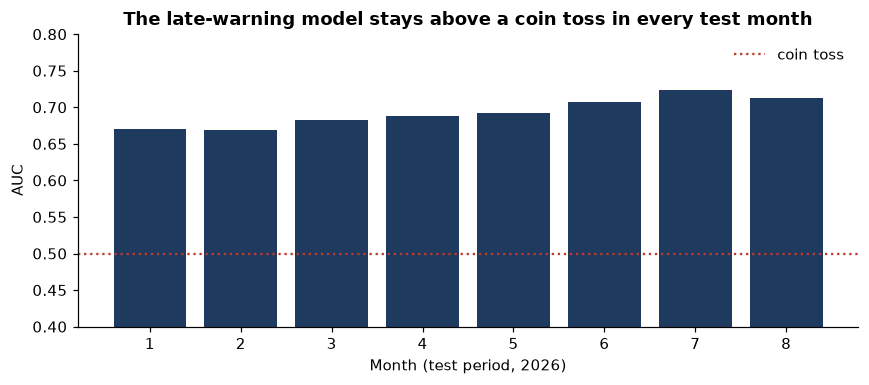

**What we see.** The AUC ranges from **0.664** to **0.723** across these groups. On disruption days it is **0.675** and on normal days **0.706**.
The model keeps its ranking ability everywhere we looked.
The weakest month is **2** (AUC 0.669), the strongest **7** (0.724).

In [7]:
def auc_of(F):
    return float(roc_auc_score(F.late, F.p_late)) if F.late.nunique() == 2 and len(F) >= 500 else np.nan
seg = []
for name, mask in [("All test turnarounds", np.ones(len(te), bool)), ("Normal days only", ~te.storm.values), ("Disruption days only", te.storm.values),
                   ("Ten busiest airports", te.hub.values == 1), ("Other airports", te.hub.values == 0),
                   ("Morning (05-11)", te.hr.between(5, 11).values), ("Afternoon (12-16)", te.hr.between(12, 16).values), ("Evening (17-23)", te.hr.between(17, 23).values)]:
    F = te[mask]
    seg.append(dict(group=name, turnarounds=len(F), late_rate=float(F.late.mean()) if len(F) else np.nan, AUC=auc_of(F)))
segtab = pd.DataFrame(seg); display(segtab.round(3).set_index("group"))
months = te.groupby("Month").apply(lambda F: pd.Series(dict(turnarounds=len(F), late_rate=F.late.mean(), AUC=auc_of(F)))); display(months.round(3))
RESULTS["segments"] = seg; RESULTS["by_month"] = months.reset_index().to_dict(orient="records")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(months.index.astype(str), months.AUC, color=BLUE); ax.axhline(0.5, color=RED, ls=":", label="coin toss"); ax.set_ylim(0.4, max(0.8, months.AUC.max() + 0.05))
ax.set_xlabel("Month (test period, 2026)"); ax.set_ylabel("AUC"); ax.set_title("The late-warning model stays above a coin toss in every test month"); ax.legend()
save(fig, "fig08_auc_by_month")
lo_, hi_ = segtab.AUC.min(), segtab.AUC.max()
say(f"""**What we see.** The AUC ranges from **{lo_:.3f}** to **{hi_:.3f}** across these groups. On disruption days it is **{segtab.set_index('group').loc['Disruption days only','AUC']:.3f}** and on normal days **{segtab.set_index('group').loc['Normal days only','AUC']:.3f}**.
{"The model keeps its ranking ability everywhere we looked." if lo_ > 0.55 else "In at least one group the ranking is weak, so we should not use the model blindly there."}
The weakest month is **{int(months.AUC.idxmin())}** (AUC {months.AUC.min():.3f}), the strongest **{int(months.AUC.idxmax())}** ({months.AUC.max():.3f}).""")

## 6. What the model learned

**Feature importance** shows how much each input helped the model, measured by the improvement it brought when the model split on it. Bigger bar = more useful input.
This is a description of the model, not proof of cause: an input can be useful because it stands in for something else (for example, `station` stands in for the congestion and weather typical of that airport).

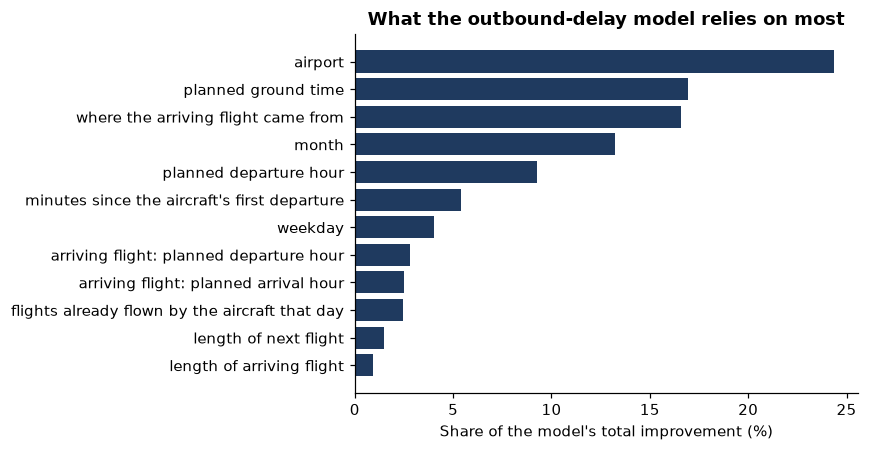

The three inputs that matter most are **airport** (24%), **planned ground time** (17%) and **where the arriving flight came from** (17%). The D3 analysis found that delay builds up through the aircraft's day; here 'flights already flown by the aircraft that day' ranks number 10 of 12 inputs.

In [8]:
imp = pd.Series(reg.booster_.feature_importance("gain"), index=FEATS); imp = (100 * imp / imp.sum()).sort_values()
nice = {"hr": "planned departure hour", "station": "airport", "sg": "planned ground time", "legno": "flights already flown by the aircraft that day", "mins_since_first": "minutes since the aircraft's first departure",
        "prev_origin": "where the arriving flight came from", "Month": "month", "DayOfWeek": "weekday", "Distance": "length of next flight", "prev_dist": "length of arriving flight",
        "prev_dep_hr": "arriving flight: planned departure hour", "prev_arr_hr": "arriving flight: planned arrival hour"}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([nice[i] for i in imp.index], imp.values, color=BLUE); ax.set_xlabel("Share of the model's total improvement (%)"); ax.set_title("What the outbound-delay model relies on most")
save(fig, "fig09_feature_importance")
RESULTS["importance"] = {k: float(v) for k, v in imp.sort_values(ascending=False).items()}
top3 = imp.sort_values(ascending=False).head(3)
say(f"The three inputs that matter most are **{nice[top3.index[0]]}** ({top3.iloc[0]:.0f}%), **{nice[top3.index[1]]}** ({top3.iloc[1]:.0f}%) and **{nice[top3.index[2]]}** ({top3.iloc[2]:.0f}%). "
    f"The D3 analysis found that delay builds up through the aircraft's day; here 'flights already flown by the aircraft that day' ranks number {int((imp.sort_values(ascending=False).index.get_loc('legno')) + 1)} of {len(imp)} inputs.")

## 7. Model B: predicting the delay that needs absorbing (inbound risk)

The buffer engine must decide *before the day* where extra ground time will help. What an extra minute can absorb is the **inbound delay** (how late the arriving aircraft is).
So Model B predicts the inbound delay in minutes (counting early arrivals as zero) from the timetable alone. We judge it by **ranking**: do turnarounds with higher predicted inbound delay really have bigger inbound delays?

Model B stopped at 241 trees


,MAE_model,MAE_average,rank_correlation,R2
period,,,,
validate,17.217,20.676,0.249,0.115
test,19.370,21.945,0.310,0.151


,turnarounds,predicted_inbound_delay,actual_inbound_delay,share_inbound_late
rdec,,,,
1,42528,2.48,3.32,0.16
2,42528,4.59,4.73,0.21
3,42526,6.19,6.15,0.25
4,42529,7.85,7.52,0.27
5,42525,9.73,9.78,0.32
6,42527,12.00,11.52,0.35
7,42527,14.91,14.16,0.39
8,42527,19.09,18.62,0.44
9,42527,26.13,24.14,0.49


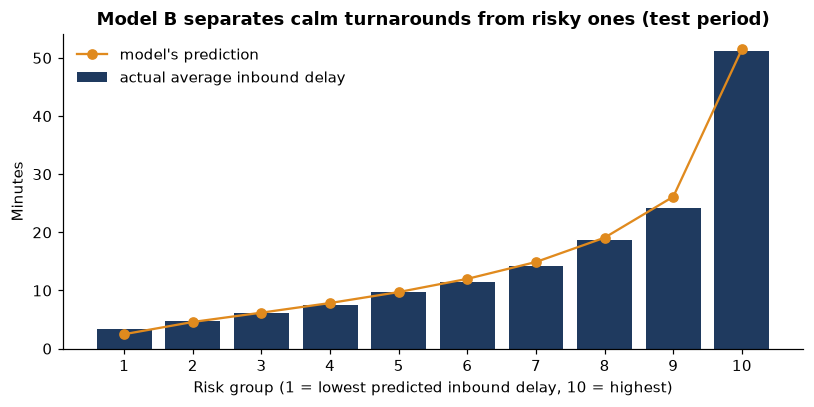

**What we see.** On the test period, the rank correlation between predicted and actual inbound delay is **0.31**.
The highest-risk tenth really has an average inbound delay of **51.2 minutes**, against **3.3** for the lowest tenth (**15.4 times** more).
The model does not predict exact minutes, but it clearly **separates the turnarounds where there will be something to absorb from the ones where there will not**. That is exactly what the buffer simulator in notebook 06 uses.

In [9]:
regB = lgb.LGBMRegressor(**params)
regB.fit(tr[FEATS], tr.Apos, eval_set=[(va[FEATS], va.Apos)], eval_metric="l1", callbacks=[lgb.early_stopping(50, verbose=False)])
print(f"Model B stopped at {regB.best_iteration_} trees")
te["risk"] = regB.predict(te[FEATS]); va_ = va.copy(); va_["risk"] = regB.predict(va[FEATS])
rows = []
for s, F in [("validate", va_), ("test", te)]:
    rho = float(pd.Series(F.risk.values).rank().corr(pd.Series(F.Apos.values).rank()))
    rows.append(dict(period=s, MAE_model=float(np.abs(F.Apos - F.risk).mean()), MAE_average=float(np.abs(F.Apos - tr.Apos.mean()).mean()), rank_correlation=rho,
                     R2=scores(F.Apos.values, F.risk.values)["R2"]))
tabB = pd.DataFrame(rows); display(tabB.round(3).set_index("period")); RESULTS["model_B"] = rows
te["rdec"] = pd.qcut(te.risk, 10, labels=False, duplicates="drop") + 1
dec = te.groupby("rdec").agg(turnarounds=("Apos", "size"), predicted_inbound_delay=("risk", "mean"), actual_inbound_delay=("Apos", "mean"), share_inbound_late=("Apos", lambda x: (x > 0).mean()))
display(dec.round(2))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(dec.index.astype(str), dec.actual_inbound_delay, color=BLUE, label="actual average inbound delay"); ax.plot(dec.index.astype(str), dec.predicted_inbound_delay, "o-", color=ORANGE, label="model's prediction")
ax.set_xlabel("Risk group (1 = lowest predicted inbound delay, 10 = highest)"); ax.set_ylabel("Minutes"); ax.set_title("Model B separates calm turnarounds from risky ones (test period)"); ax.legend()
save(fig, "fig10_inbound_risk_deciles")
ratioB = float(dec.actual_inbound_delay.iloc[-1] / max(dec.actual_inbound_delay.iloc[0], 1e-9))
RESULTS["inbound_risk_deciles"] = dec.reset_index().to_dict(orient="records"); RESULTS["inbound_ratio_top_bottom"] = ratioB
say(f"""**What we see.** On the test period, the rank correlation between predicted and actual inbound delay is **{tabB.set_index('period').loc['test','rank_correlation']:.2f}**.
The highest-risk tenth really has an average inbound delay of **{dec.actual_inbound_delay.iloc[-1]:.1f} minutes**, against **{dec.actual_inbound_delay.iloc[0]:.1f}** for the lowest tenth (**{ratioB:.1f} times** more).
The model does not predict exact minutes, but it clearly **separates the turnarounds where there will be something to absorb from the ones where there will not**. That is exactly what the buffer simulator in notebook 06 uses.""")

## 8. Summary of notebook 05, with its limits

In [10]:
A_ = regtab[regtab.period == "test"].set_index("predictor"); L_ = RESULTS["lift"]
say(f"""**Results on the test period (Jan to Aug 2026), which the model never saw during training or tuning:**

1. **Outbound delay in minutes:** average error {A_.loc['4 LightGBM model','MAE']:.1f} min against {A_.loc['1 Training average','MAE']:.1f} for the plain average; R² {A_.loc['4 LightGBM model','R2']:.2f}. Modest, as expected from a timetable-only model.
2. **15-minute-late warning:** AUC {L_['auc']:.3f} (baseline {L_['auc_baseline']:.3f}). The riskiest tenth is late {100*L_['top_decile']:.0f}% of the time and the safest tenth {100*L_['bottom_decile']:.0f}%.
3. **Inbound risk (Model B):** the riskiest tenth has {RESULTS['inbound_ratio_top_bottom']:.1f} times the inbound delay of the safest tenth, so there is real signal to guide buffer.
4. **Robustness:** ranking power stays above a coin toss on disruption days, at the busiest airports and elsewhere, and in every test month.

**Limits, stated plainly:**
* The models use only timetable facts, so they cannot know about weather, faults or crew. They rank risk; they do not forecast an exact delay.
* We only have turnarounds where *both* flights operated. Cancelled and diverted flights are not predicted.
* The data cover one airline and 20 months; each calendar month appears once or twice. A model learned on 2025 is tested on 2026, which is a fair "future" test, but seasonal patterns are thinly covered.
* Feature importance describes the model, it does not prove cause.
* We did not tune the models heavily. Better tuning may add a little; it will not change the main conclusion.""")
write_results("results_05_model.json")

**Results on the test period (Jan to Aug 2026), which the model never saw during training or tuning:**

1. **Outbound delay in minutes:** average error 25.0 min against 26.8 for the plain average; R² 0.07. Modest, as expected from a timetable-only model.
2. **15-minute-late warning:** AUC 0.703 (baseline 0.619). The riskiest tenth is late 64% of the time and the safest tenth 11%.
3. **Inbound risk (Model B):** the riskiest tenth has 15.4 times the inbound delay of the safest tenth, so there is real signal to guide buffer.
4. **Robustness:** ranking power stays above a coin toss on disruption days, at the busiest airports and elsewhere, and in every test month.

**Limits, stated plainly:**
* The models use only timetable facts, so they cannot know about weather, faults or crew. They rank risk; they do not forecast an exact delay.
* We only have turnarounds where *both* flights operated. Cancelled and diverted flights are not predicted.
* The data cover one airline and 20 months; each calendar month appears once or twice. A model learned on 2025 is tested on 2026, which is a fair "future" test, but seasonal patterns are thinly covered.
* Feature importance describes the model, it does not prove cause.
* We did not tune the models heavily. Better tuning may add a little; it will not change the main conclusion.

Saved results_05_model.json and 7 chart files in the folder 'modelling_outputs'.
